In [1]:
from scipy.optimize import brentq
import numpy as np
from datetime import datetime
import time, sys, os, pyvisa, subprocess
import matplotlib as mpl
import matplotlib.pyplot as plt
import time

In [1]:
from Instruments.hp34461A import *
from Instruments.vna_config import *
from Instruments.power_supply import *
from Routines.res_to_temp import *
from Routines.retrieve_vna_data import *
from Routines.vna_analysis import *
from Instruments.power_supply import *
from Routines.dep_evap import *

In [2]:
hp34461a_addr = 'GPIB0::22::INSTR'
vna_addr = 'GPIB0::16::INSTR'
port ='S21'
arduino_addr = 'COM3'

bkpower_addr = 'USB0::0x2EC7::0x9130::800885011797670040::INSTR'
lo_addr = "GPIB0::27::INSTR"

In [5]:
rm = pyvisa.ResourceManager()

rm.list_resources()


arduino = rm.open_resource('COM3')

arduino.close()

bkpower = rm.open_resource(bkpower_addr)

hp34461a = rm.open_resource(hp34461a_addr)



bkpower.close()

hp34461a.close()

VisaIOError: VI_ERROR_RSRC_BUSY (-1073807246): The resource is valid, but VISA cannot currently access it.

In [ ]:
set_current(bkpower_addr, 2, 0.6)

wait_for_stable_resistance()



In [ ]:
current_root_array = np.linspace(np.sqrt(0.600), np.sqrt(0.00), 51)

current_array = current_root_array**2

os.makedirs(r"C:\Users\crow104\Desktop\IceT_SD\SpatialNeon\Data\quenchdep_05072026", exist_ok = True)

path = r"C:\Users\crow104\Desktop\IceT_SD\SpatialNeon\Data\quenchdep_05072026"
f_values = [3.762, 3.959, 4.254, 4.425, 4.620, 4.845, 5.5157, 5.397, 5.582]


multires_liquid_cooldown_buffer(vna_addr = vna_addr, hp34461a_addr = hp34461a_addr, bkpower_addr = bkpower_addr, arduino_addr = arduino_addr, data_dir= path, current_array= current_array, buffer = 60*5, wait_time = 3, del_time = 3, f_vals = f_values, BW = 1E3, span = 80, power = -10, n_points = 201)

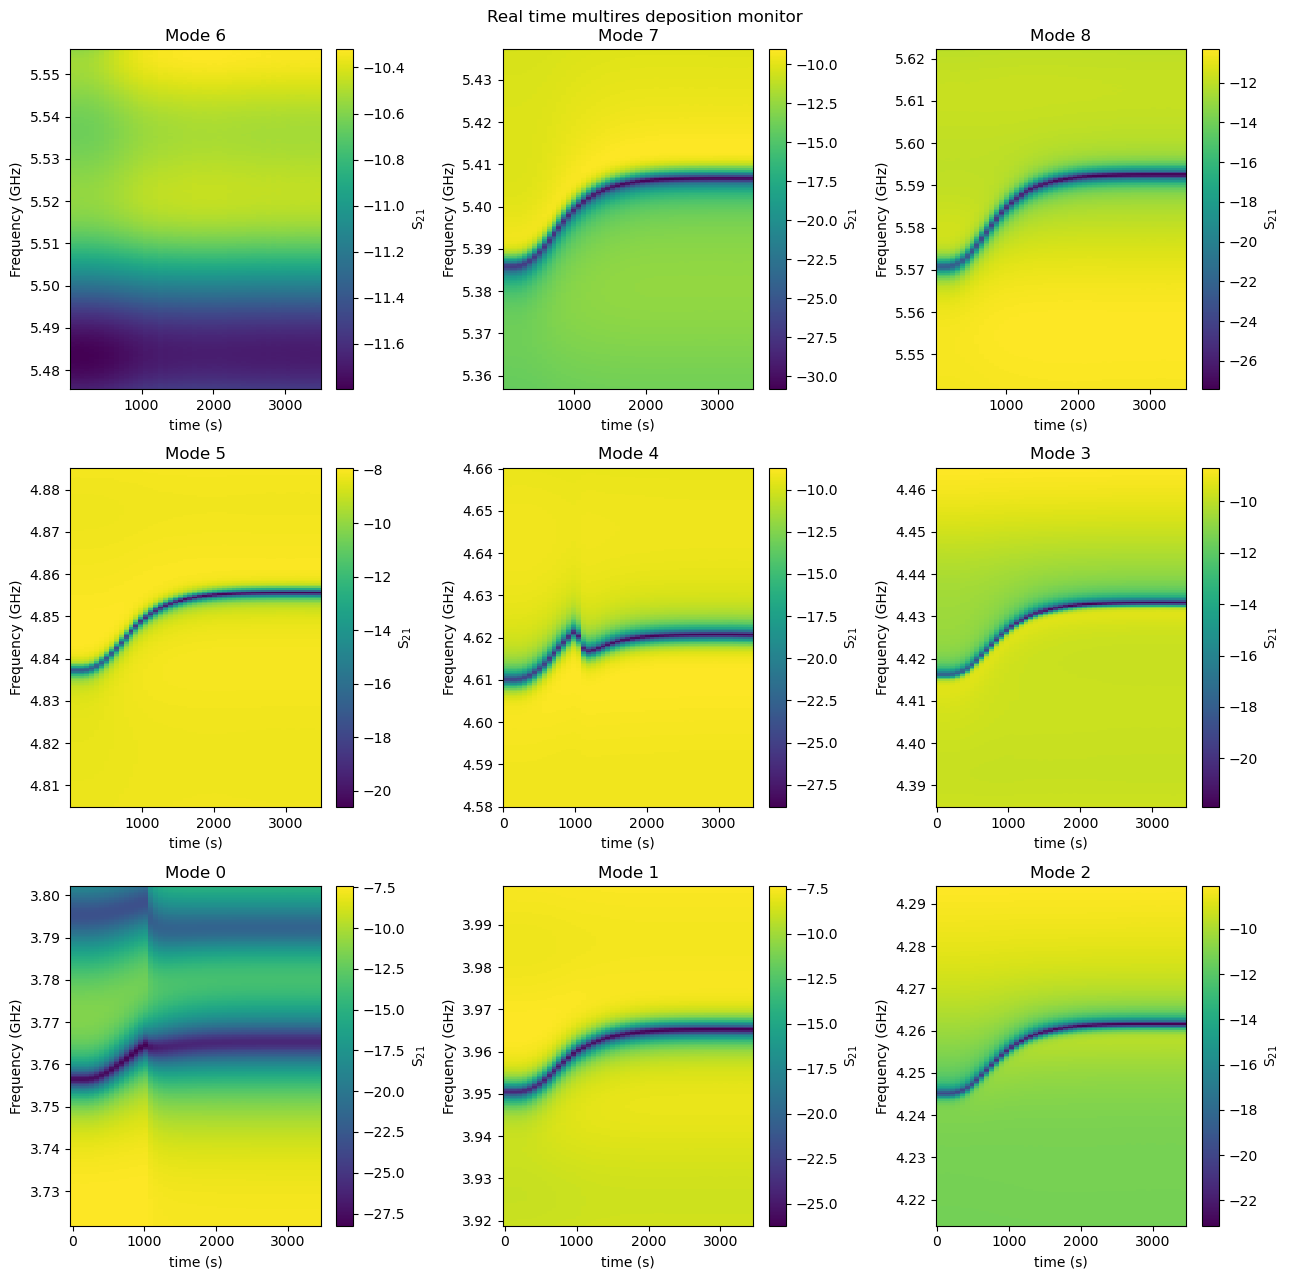

In [6]:
fig, axes = plt.subplots(3, 3, figsize=(13, 13))


time_stamp = "2026-05-08 01_51_17.294631"

name = ""

data_dir = r"C:\Users\crow104\Desktop\IceT_SD\SpatialNeon\Data\quenchdep_05072026"
# Physical chip layout (bottom-left = mode0)
layout = [
    [6, 7, 8],
    [5, 4, 3],
    [0, 1, 2]
]

for i in range(3):
    for j in range(3):
        mode = layout[i][j]
        mode_dir = os.path.join(data_dir, f"mode{mode}")

        # Load saved files
        time_axis = np.loadtxt(
            os.path.join(mode_dir, f"{time_stamp}_time_{name}.csv")
        )

        S_axis = np.loadtxt(
            os.path.join(mode_dir, f"{time_stamp}_S21_{name}.csv")
        )

        f_array = np.loadtxt(
            os.path.join(mode_dir, f"{time_stamp}_frequency_{name}.csv")
        )[0]

        # pcolor returns the mappable object needed for colorbar
        pcm = axes[i, j].pcolor(
            time_axis,
            f_array,
            S_axis,
            shading="auto"
        )

        axes[i, j].set_xlabel("time (s)")
        axes[i, j].set_ylabel("Frequency (GHz)")
        axes[i, j].set_title(f"Mode {mode}")

        # Correct way to add colorbar
        fig.colorbar(pcm, ax=axes[i, j], label="S$_{21}$")

fig.suptitle("Real time multires deposition monitor")
plt.tight_layout()
plt.show()

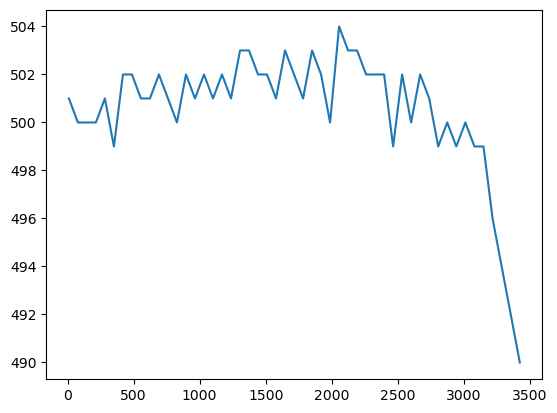

In [8]:
temp = np.loadtxt(r"C:\Users\crow104\Desktop\IceT_SD\SpatialNeon\Data\quenchdep_05072026\mode1\2026-05-08 01_51_17.294631_pressure_.csv")

time = np.loadtxt(r"C:\Users\crow104\Desktop\IceT_SD\SpatialNeon\Data\quenchdep_05072026\mode1\2026-05-08 01_51_17.294631_time_.csv")


plt.plot(time, temp)

plt.show()

In [ ]:
print(np.shape(f_array))

Channel set to 2

Voltage set to 30
V
80
Started at 2026-05-08 13_29_08.164667


c:\Users\crow104\Desktop\IceT_SD\SpatialNeon\Routines\res_to_temp.py:48: RuntimeWarning: divide by zero encountered in log
  log_T = np.log(T)


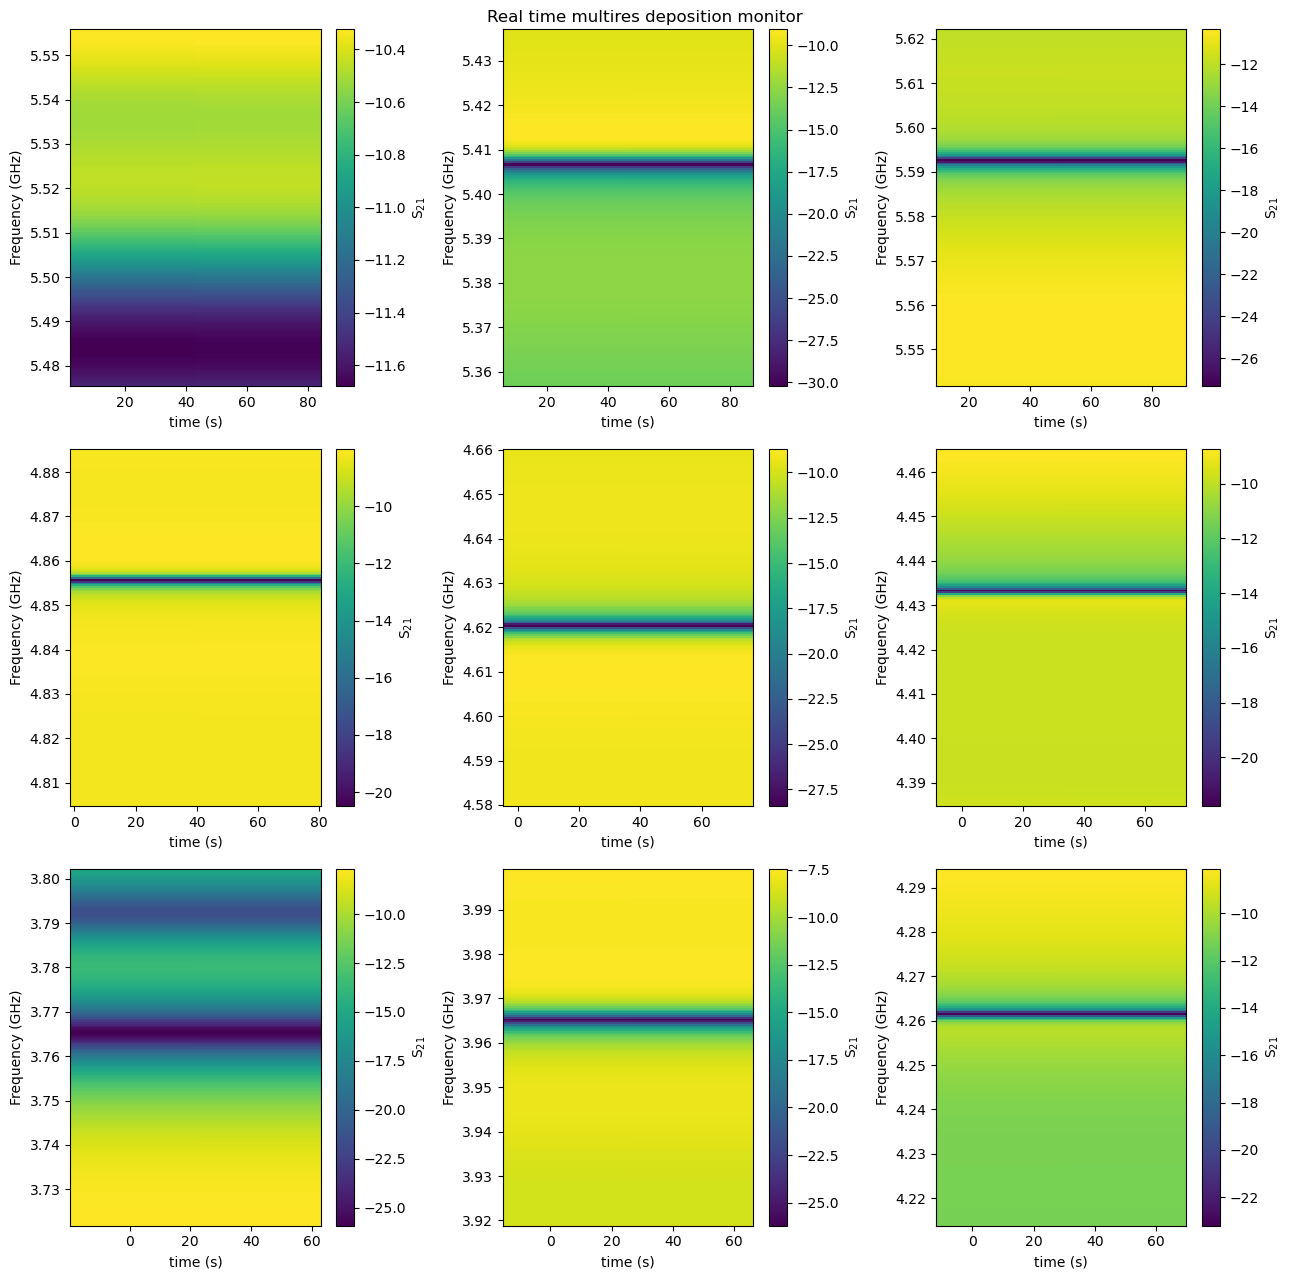

In [4]:
current_array_temp = [0.0, 0.0, 0.0]
f_array = [3.762, 3.959, 4.254, 4.425, 4.620, 4.845, 5.157, 5.397, 5.582]
os.makedirs(r"C:\Users\crow104\Desktop\IceT_SD\SpatialNeon\Data\testrun_05082026", exist_ok= True)
path = r"C:\Users\crow104\Desktop\IceT_SD\SpatialNeon\Data\testrun_05082026"
multires_liquid_cooldown_buffer(vna_addr, hp34461a_addr, bkpower_addr, arduino_addr, data_dir= path, buffer = 60*1, wait_time= 2, del_time= 1, f_vals = f_array, BW = 1E3, span = 80, power = -20)

80
Started at 2026-05-10 16_39_41.673577


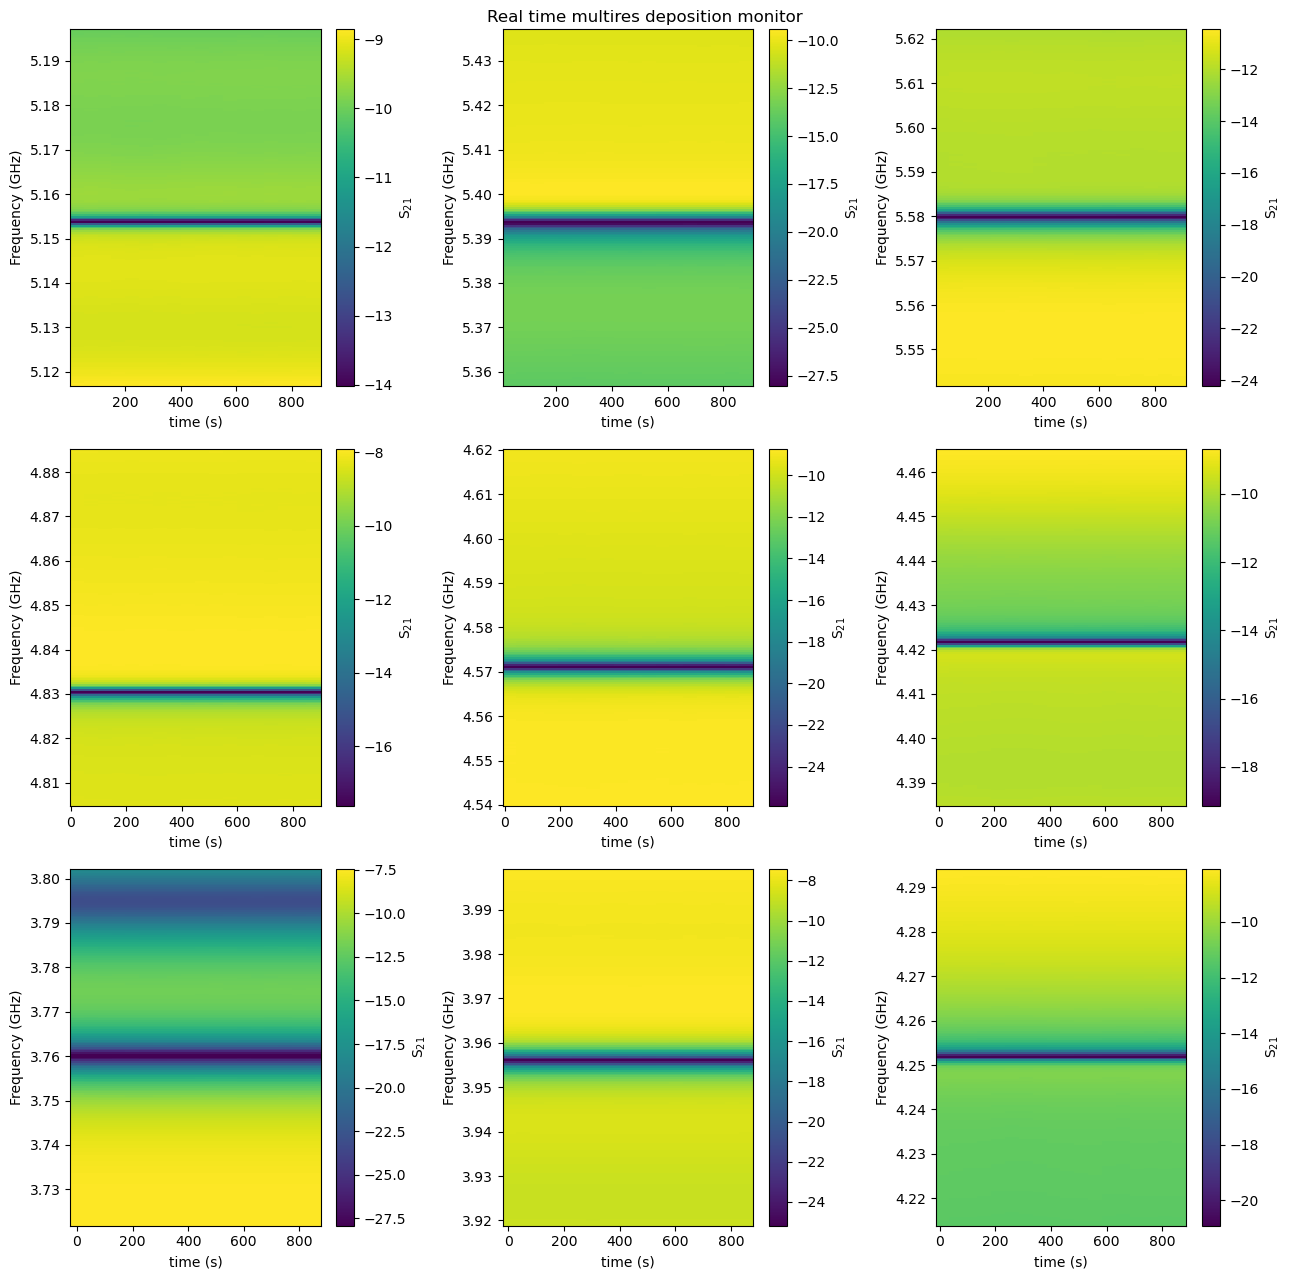

In [5]:
#current_array_temp = [0.0, 0.0, 0.0]
f_array = [3.762, 3.959, 4.254, 4.425, 4.580, 4.845, 5.157, 5.397, 5.582]
os.makedirs(r"C:\Users\crow104\Desktop\IceT_SD\SpatialNeon\Data\mfcdep_05102026", exist_ok= True)
path = r"C:\Users\crow104\Desktop\IceT_SD\SpatialNeon\Data\mfcdep_05102026"
mfc_multires_depMon(vna_addr, hp34461a_addr, arduino_addr, data_dir= path, wait_time= 60*15, delay_time= 2, del_time= 1, f_vals = f_array, BW = 1E3, span = 80, power = -20)

Channel set to 2

Voltage set to 30
V
110
Started at 2026-05-08 20_25_54.617197


c:\Users\crow104\Desktop\IceT_SD\SpatialNeon\Routines\res_to_temp.py:48: RuntimeWarning: divide by zero encountered in log
  log_T = np.log(T)


Channel set to 2

Current set to 0.55
A
Channel set to 2

Current set to 0.548563
A
Channel set to 2

Current set to 0.547128
A
Channel set to 2

Current set to 0.545695
A
Channel set to 2

Current set to 0.544263
A
Channel set to 2

Current set to 0.542834
A
Channel set to 2

Current set to 0.541406
A
Channel set to 2

Current set to 0.53998
A
Channel set to 2

Current set to 0.538556
A
Channel set to 2

Current set to 0.537134
A
Channel set to 2

Current set to 0.535714
A
Channel set to 2

Current set to 0.534296
A
Channel set to 2

Current set to 0.53288
A
Channel set to 2

Current set to 0.531465
A
Channel set to 2

Current set to 0.530052
A
Channel set to 2

Current set to 0.528642
A
Channel set to 2

Current set to 0.527233
A
Channel set to 2

Current set to 0.525826
A
Channel set to 2

Current set to 0.524421
A
Channel set to 2

Current set to 0.523018
A
Channel set to 2

Current set to 0.521616
A
Channel set to 2

Current set to 0.520217
A
Channel set to 2

Current set to 0.518

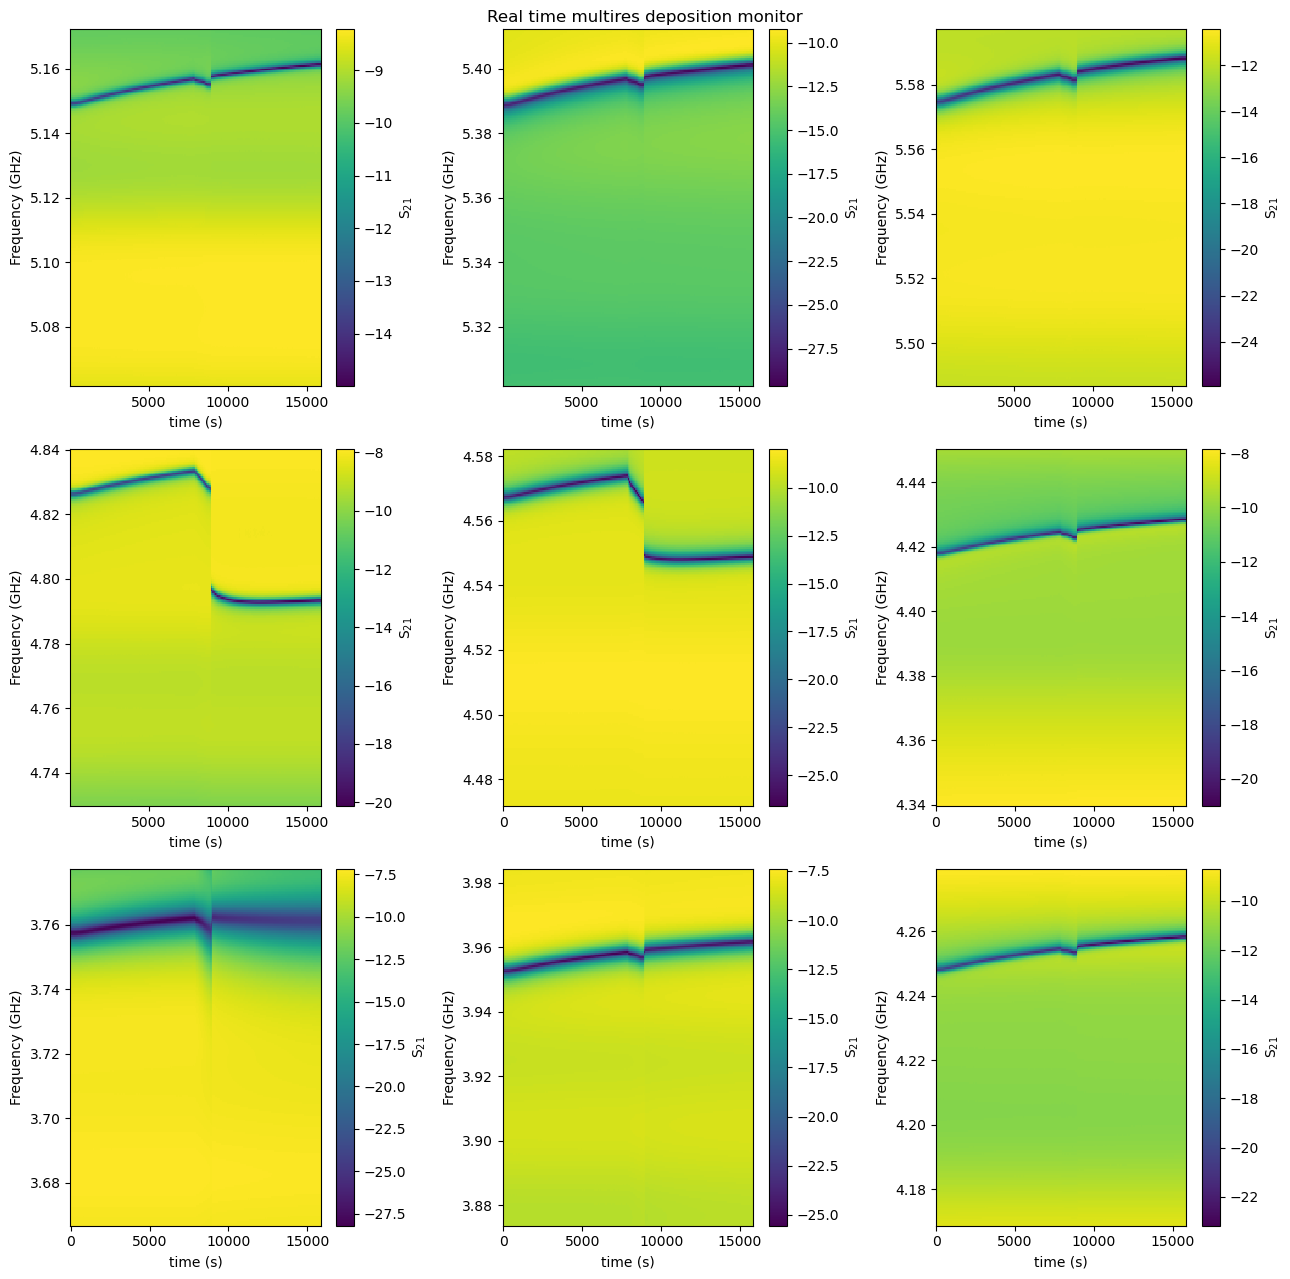

In [5]:
current_root_array = np.linspace(np.sqrt(0.550), np.sqrt(0.300), 201)

current_array = current_root_array**2

os.makedirs(r"C:\Users\crow104\Desktop\IceT_SD\SpatialNeon\Data\LtoS_05082026", exist_ok = True)

path = r"C:\Users\crow104\Desktop\IceT_SD\SpatialNeon\Data\LtoS_05082026"
f_values = [3.722, 3.929, 4.224, 4.395, 4.527, 4.785, 5.117, 5.357, 5.542]


multires_liquid_cooldown_buffer(vna_addr = vna_addr, hp34461a_addr = hp34461a_addr, bkpower_addr = bkpower_addr, arduino_addr = arduino_addr, data_dir= path, current_array= current_array, buffer = 60*5, delay_time = 3, del_time = 3, f_vals = f_values, BW = 1E3, span = 110, power = -10, n_points = 201)

Channel set to 2

Voltage set to 30
V
60
Started at 2026-05-09 14_24_14.597089


c:\Users\crow104\Desktop\IceT_SD\SpatialNeon\Routines\res_to_temp.py:48: RuntimeWarning: divide by zero encountered in log
  log_T = np.log(T)


Channel set to 2

Current set to 0.55
A
Channel set to 2

Current set to 0.548563
A
Channel set to 2

Current set to 0.547128
A
Channel set to 2

Current set to 0.545695
A
Channel set to 2

Current set to 0.544263
A
Channel set to 2

Current set to 0.542834
A
Channel set to 2

Current set to 0.541406
A
Channel set to 2

Current set to 0.53998
A
Channel set to 2

Current set to 0.538556
A
Channel set to 2

Current set to 0.537134
A
Channel set to 2

Current set to 0.535714
A
Channel set to 2

Current set to 0.534296
A
Channel set to 2

Current set to 0.53288
A
Channel set to 2

Current set to 0.531465
A
Channel set to 2

Current set to 0.530052
A
Channel set to 2

Current set to 0.528642
A
Channel set to 2

Current set to 0.527233
A
Channel set to 2

Current set to 0.525826
A
Channel set to 2

Current set to 0.524421
A
Channel set to 2

Current set to 0.523018
A
Channel set to 2

Current set to 0.521616
A
Channel set to 2

Current set to 0.520217
A
Channel set to 2

Current set to 0.518

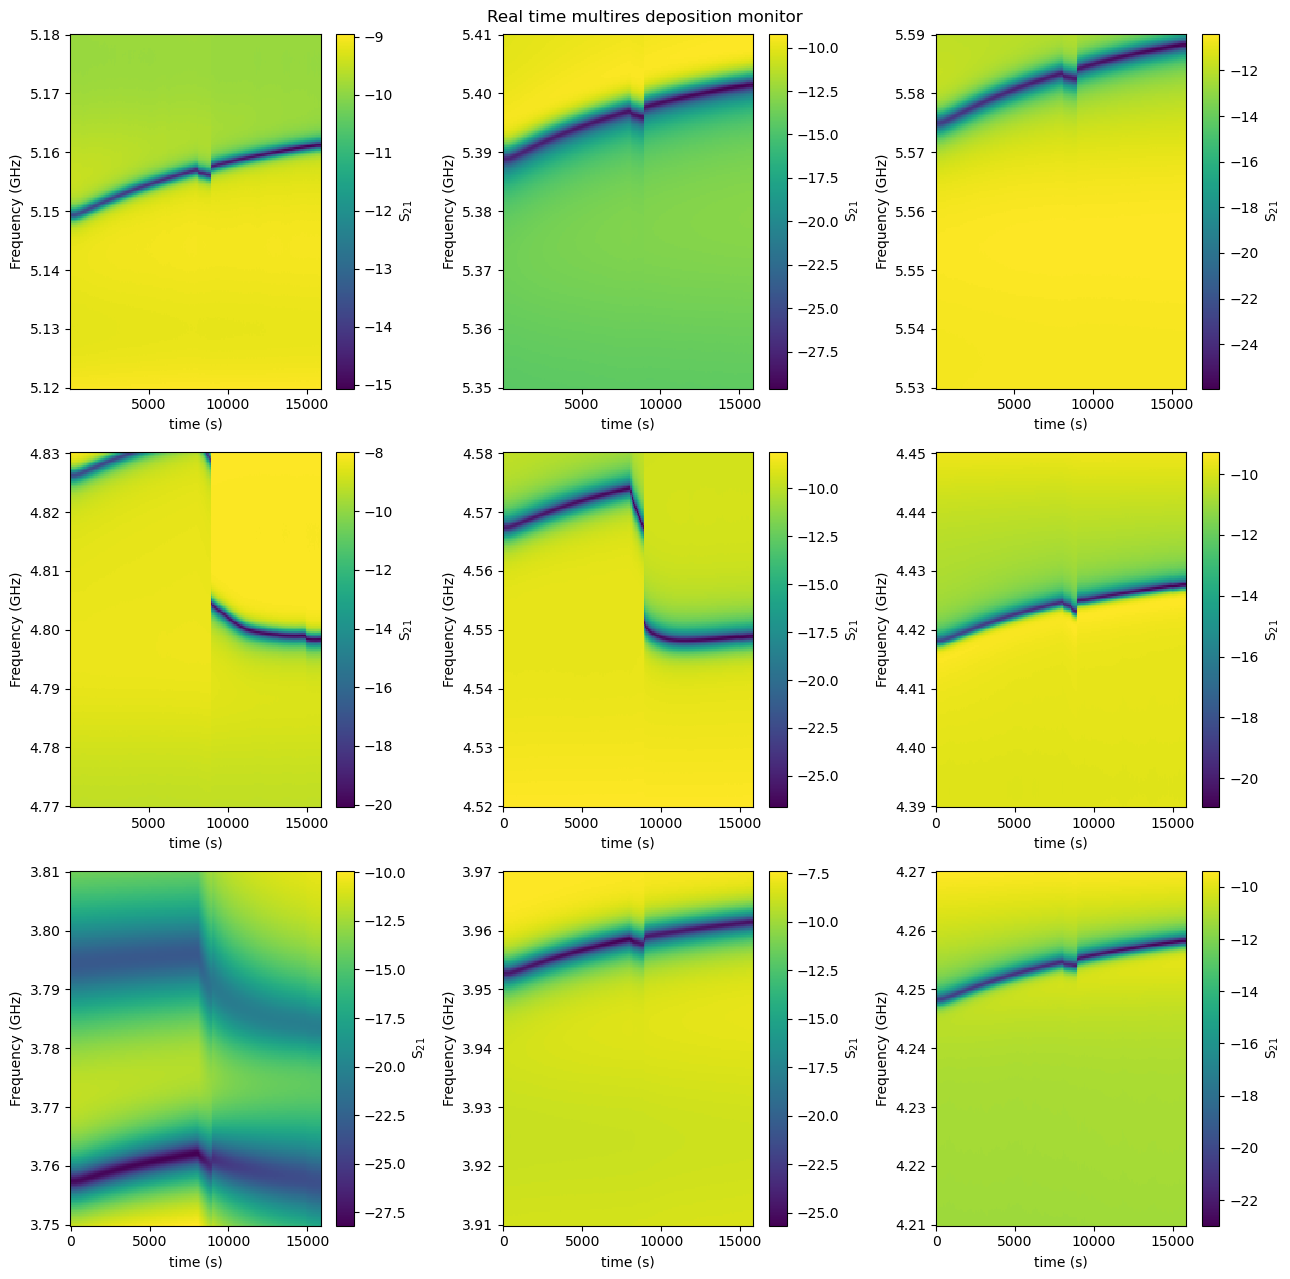

In [6]:
current_root_array = np.linspace(np.sqrt(0.550), np.sqrt(0.300), 201)

current_array = current_root_array**2

os.makedirs(r"C:\Users\crow104\Desktop\IceT_SD\SpatialNeon\Data\LtoS_05092026", exist_ok = True)

path = r"C:\Users\crow104\Desktop\IceT_SD\SpatialNeon\Data\LtoS_05092026"
f_values = [3.78, 3.94, 4.24, 4.42, 4.55, 4.80, 5.15, 5.38, 5.56]


multires_liquid_cooldown_buffer(vna_addr = vna_addr, hp34461a_addr = hp34461a_addr, bkpower_addr = bkpower_addr, arduino_addr = arduino_addr, data_dir= path, current_array= current_array, buffer = 60*5, delay_time = 3, del_time = 3, f_vals = f_values, BW = 1E3, span = 60, power = -20, n_points = 201, name = 'powerminus20')

c:\Users\crow104\Desktop\IceT_SD\SpatialNeon\Routines\res_to_temp.py:48: RuntimeWarning: divide by zero encountered in log
  log_T = np.log(T)


success!
Channel set to 2

Voltage set to 30
V
60
Started at 2026-05-10 03_41_45.602496
Channel set to 2

Current set to 0.55
A
Channel set to 2

Current set to 0.548563
A
Channel set to 2

Current set to 0.547128
A
Channel set to 2

Current set to 0.545695
A
Channel set to 2

Current set to 0.544263
A
Channel set to 2

Current set to 0.542834
A
Channel set to 2

Current set to 0.541406
A
Channel set to 2

Current set to 0.53998
A
Channel set to 2

Current set to 0.538556
A
Channel set to 2

Current set to 0.537134
A
Channel set to 2

Current set to 0.535714
A
Channel set to 2

Current set to 0.534296
A
Channel set to 2

Current set to 0.53288
A
Channel set to 2

Current set to 0.531465
A
Channel set to 2

Current set to 0.530052
A
Channel set to 2

Current set to 0.528642
A
Channel set to 2

Current set to 0.527233
A
Channel set to 2

Current set to 0.525826
A
Channel set to 2

Current set to 0.524421
A
Channel set to 2

Current set to 0.523018
A
Channel set to 2

Current set to 0.521

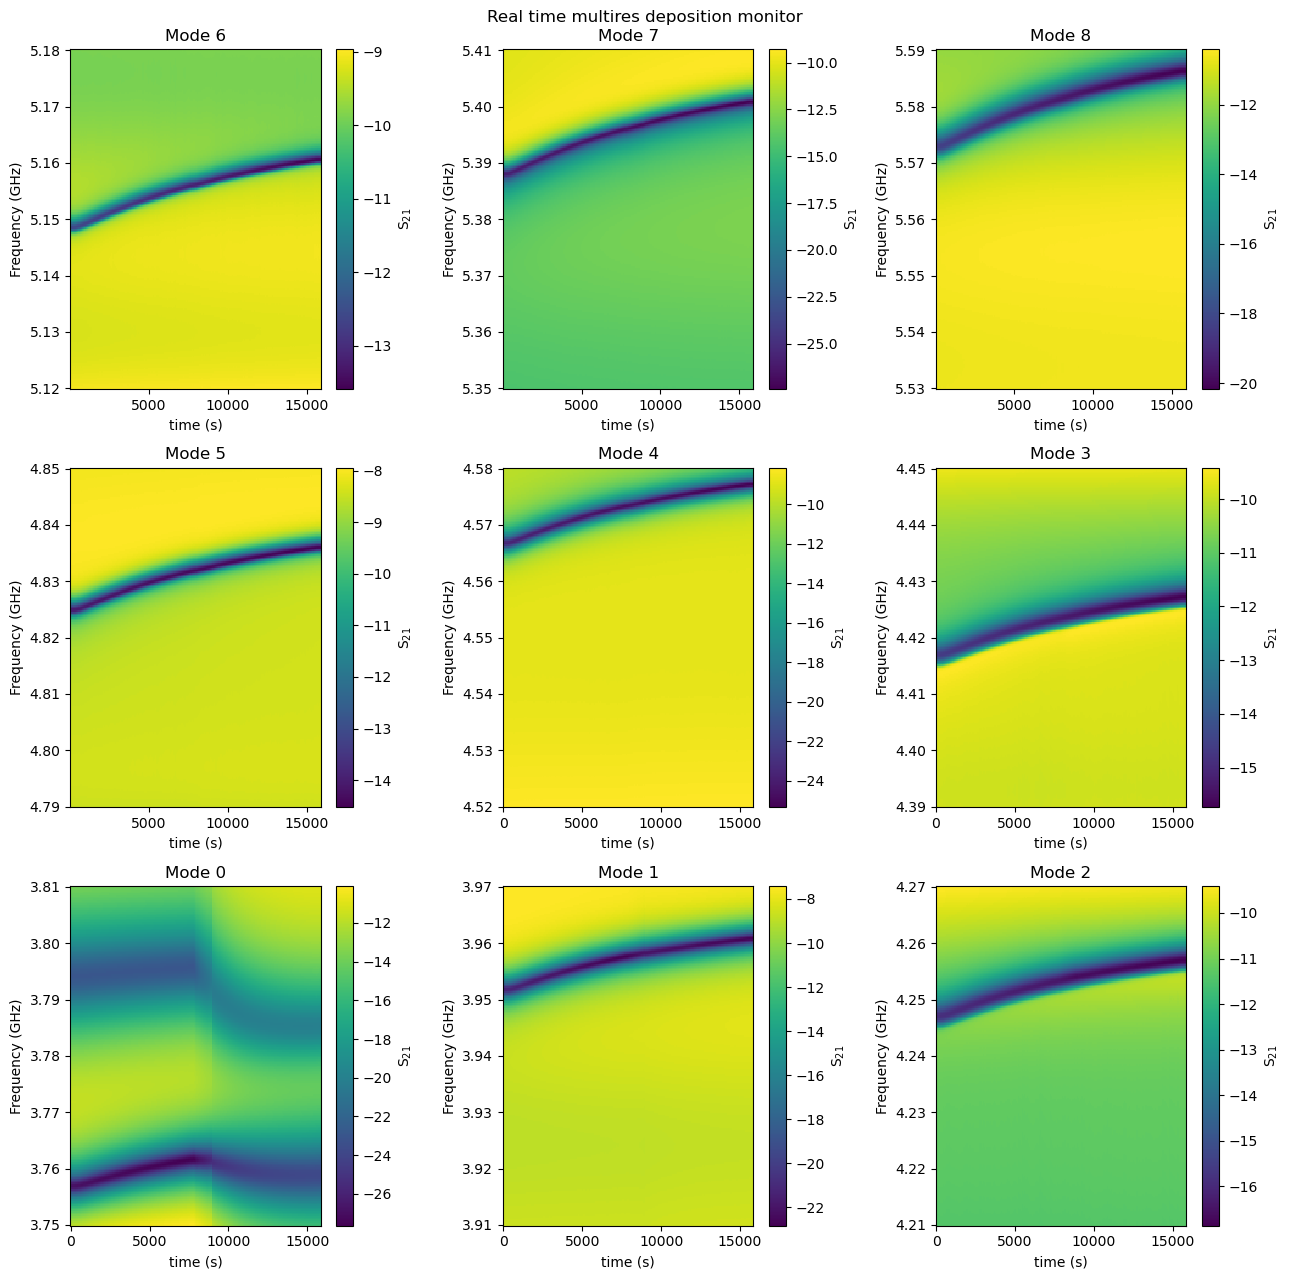

In [4]:
wait_for_stable_resistance()

current_root_array = np.linspace(np.sqrt(0.550), np.sqrt(0.300), 201)

current_array = current_root_array**2

os.makedirs(r"C:\Users\crow104\Desktop\IceT_SD\SpatialNeon\Data\LtoS_05102026", exist_ok = True)

path = r"C:\Users\crow104\Desktop\IceT_SD\SpatialNeon\Data\LtoS_05102026"
f_values = [3.78, 3.94, 4.24, 4.42, 4.55, 4.82, 5.15, 5.38, 5.56]


multires_liquid_cooldown_buffer(vna_addr = vna_addr, hp34461a_addr = hp34461a_addr, bkpower_addr = bkpower_addr, arduino_addr = arduino_addr, data_dir= path, current_array= current_array, buffer = 60*5, delay_time = 3, del_time = 3, f_vals = f_values, BW = 1E3, span = 60, power = 10, n_points = 201, name = 'powerminus20')

Channel set to 2

Voltage set to 30
V
60
Started at 2026-05-10 18_30_34.460307


c:\Users\crow104\Desktop\IceT_SD\SpatialNeon\Routines\res_to_temp.py:48: RuntimeWarning: divide by zero encountered in log
  log_T = np.log(T)


Channel set to 2

Current set to 0.48
A
Channel set to 2

Current set to 0.478995
A
Channel set to 2

Current set to 0.477992
A
Channel set to 2

Current set to 0.476989
A
Channel set to 2

Current set to 0.475987
A
Channel set to 2

Current set to 0.474987
A
Channel set to 2

Current set to 0.473987
A
Channel set to 2

Current set to 0.472989
A
Channel set to 2

Current set to 0.471992
A
Channel set to 2

Current set to 0.470995
A
Channel set to 2

Current set to 0.47
A
Channel set to 2

Current set to 0.469006
A
Channel set to 2

Current set to 0.468013
A
Channel set to 2

Current set to 0.46702
A
Channel set to 2

Current set to 0.466029
A
Channel set to 2

Current set to 0.465039
A
Channel set to 2

Current set to 0.46405
A
Channel set to 2

Current set to 0.463063
A
Channel set to 2

Current set to 0.462076
A
Channel set to 2

Current set to 0.46109
A
Channel set to 2

Current set to 0.460105
A
Channel set to 2

Current set to 0.459121
A
Channel set to 2

Current set to 0.458139
A

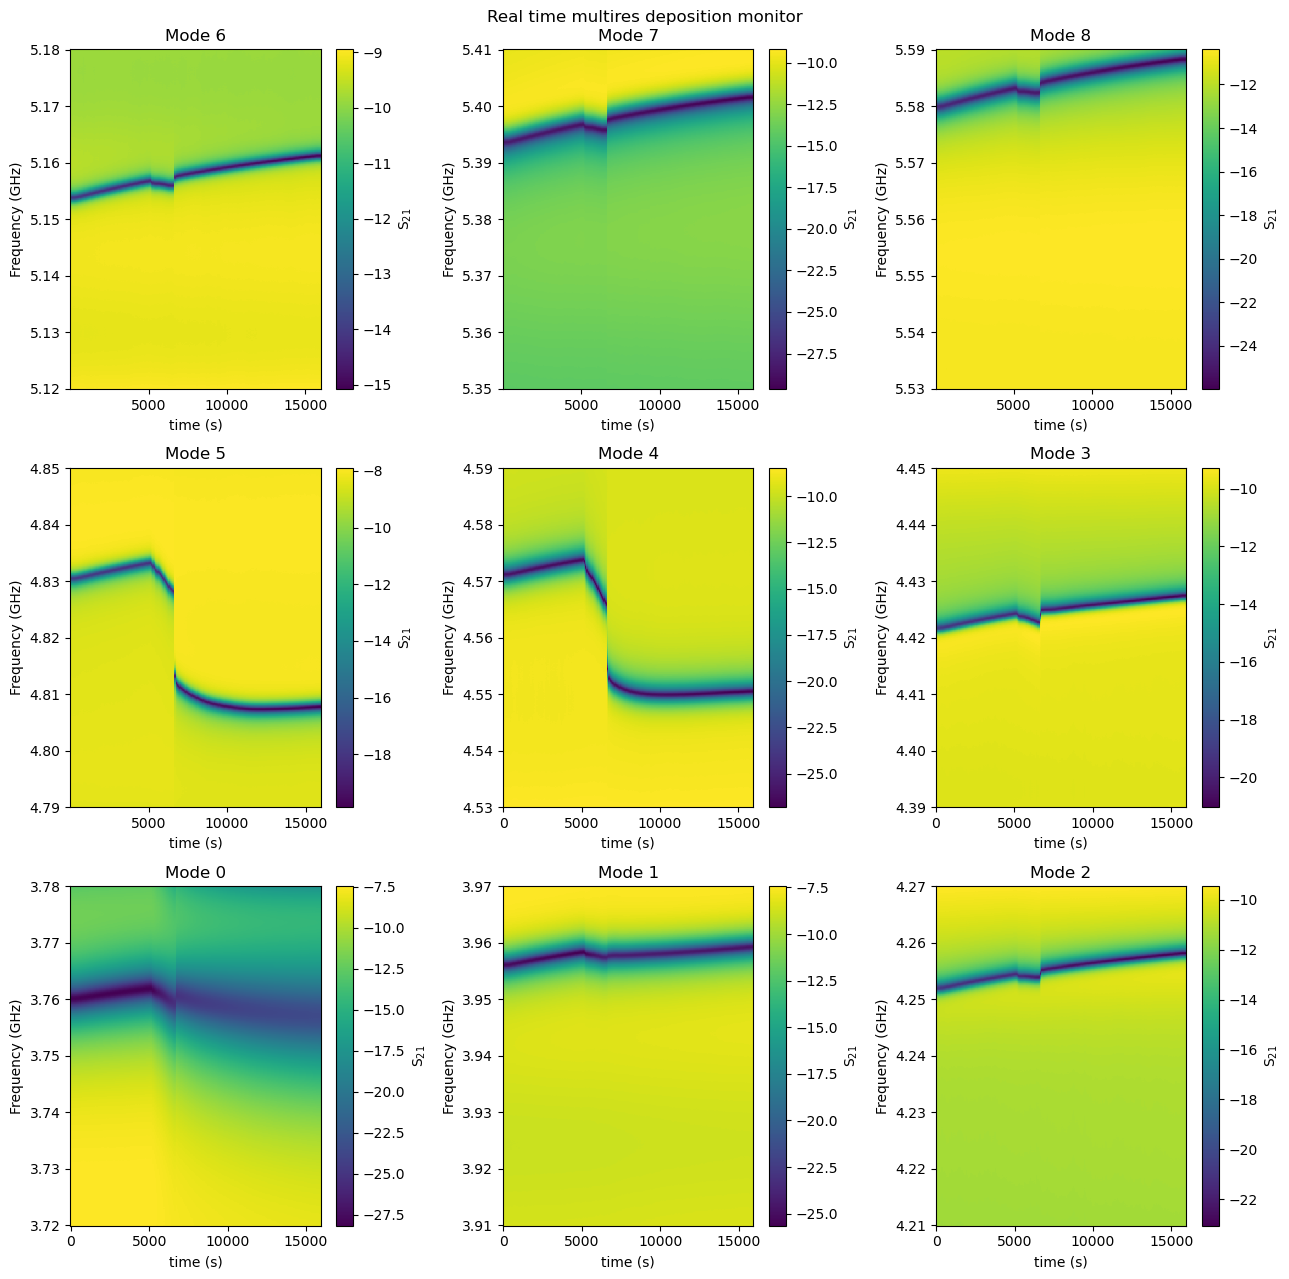

In [4]:


current_root_array = np.linspace(np.sqrt(0.480), np.sqrt(0.300), 201)

current_array = current_root_array**2

os.makedirs(r"C:\Users\crow104\Desktop\IceT_SD\SpatialNeon\Data\LtoS2_05102026", exist_ok = True)

path = r"C:\Users\crow104\Desktop\IceT_SD\SpatialNeon\Data\LtoS2_05102026"
f_values = [3.75, 3.94, 4.24, 4.42, 4.56, 4.82, 5.15, 5.38, 5.56]


multires_liquid_cooldown_buffer(vna_addr = vna_addr, hp34461a_addr = hp34461a_addr, bkpower_addr = bkpower_addr, arduino_addr = arduino_addr, data_dir= path, current_array= current_array, buffer = 60*5, wait_time= 60, delay_time = 3, del_time = 3, f_vals = f_values, BW = 1E3, span = 60, power = -20, n_points = 501, name = 'powerminus20')

c:\Users\crow104\Desktop\IceT_SD\SpatialNeon\Routines\res_to_temp.py:48: RuntimeWarning: divide by zero encountered in log
  log_T = np.log(T)


success!
Channel set to 2

Voltage set to 30
V
60
Started at 2026-05-11 13_10_09.418000
Channel set to 2

Current set to 0.48
A
Channel set to 2

Current set to 0.478995
A
Channel set to 2

Current set to 0.477992
A
Channel set to 2

Current set to 0.476989
A
Channel set to 2

Current set to 0.475987
A
Channel set to 2

Current set to 0.474987
A
Channel set to 2

Current set to 0.473987
A
Channel set to 2

Current set to 0.472989
A
Channel set to 2

Current set to 0.471992
A
Channel set to 2

Current set to 0.470995
A
Channel set to 2

Current set to 0.47
A
Channel set to 2

Current set to 0.469006
A
Channel set to 2

Current set to 0.468013
A
Channel set to 2

Current set to 0.46702
A
Channel set to 2

Current set to 0.466029
A
Channel set to 2

Current set to 0.465039
A
Channel set to 2

Current set to 0.46405
A
Channel set to 2

Current set to 0.463063
A
Channel set to 2

Current set to 0.462076
A
Channel set to 2

Current set to 0.46109
A
Channel set to 2

Current set to 0.460105
A

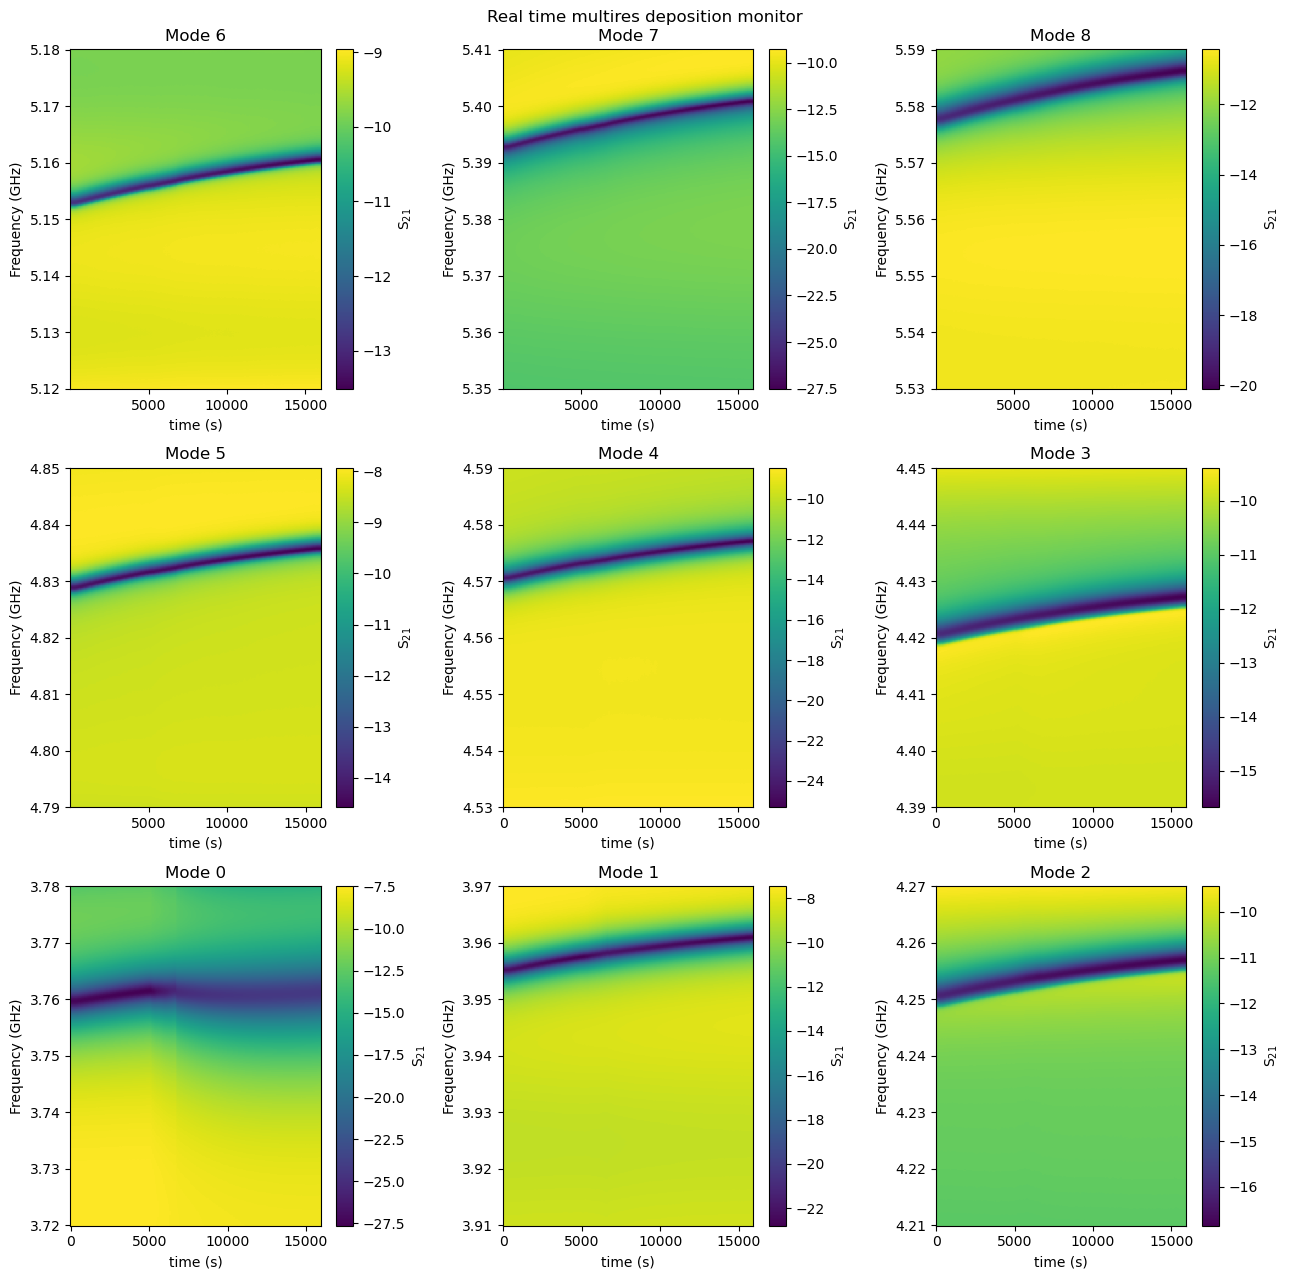

In [5]:
wait_for_stable_resistance()

current_root_array = np.linspace(np.sqrt(0.480), np.sqrt(0.300), 201)

current_array = current_root_array**2

os.makedirs(r"C:\Users\crow104\Desktop\IceT_SD\SpatialNeon\Data\LtoS_05112026", exist_ok = True)

path = r"C:\Users\crow104\Desktop\IceT_SD\SpatialNeon\Data\LtoS_05112026"
f_values = [3.75, 3.94, 4.24, 4.42, 4.56, 4.82, 5.15, 5.38, 5.56]


multires_liquid_cooldown_buffer(vna_addr = vna_addr, hp34461a_addr = hp34461a_addr, bkpower_addr = bkpower_addr, arduino_addr = arduino_addr, data_dir= path, current_array= current_array, buffer = 60*5, wait_time= 60, delay_time = 3, del_time = 3, f_vals = f_values, BW = 1E3, span = 60, power = 10, n_points = 501, name = 'power10')

success!
Channel set to 2

Voltage set to 30
V
60
Started at 2026-05-11 18_18_04.511590
Channel set to 2

Current set to 0.48
A
Channel set to 2

Current set to 0.478995
A
Channel set to 2

Current set to 0.477992
A
Channel set to 2

Current set to 0.476989
A
Channel set to 2

Current set to 0.475987
A
Channel set to 2

Current set to 0.474987
A
Channel set to 2

Current set to 0.473987
A
Channel set to 2

Current set to 0.472989
A
Channel set to 2

Current set to 0.471992
A
Channel set to 2

Current set to 0.470995
A
Channel set to 2

Current set to 0.47
A
Channel set to 2

Current set to 0.469006
A
Channel set to 2

Current set to 0.468013
A
Channel set to 2

Current set to 0.46702
A
Channel set to 2

Current set to 0.466029
A
Channel set to 2

Current set to 0.465039
A
Channel set to 2

Current set to 0.46405
A
Channel set to 2

Current set to 0.463063
A
Channel set to 2

Current set to 0.462076
A
Channel set to 2

Current set to 0.46109
A
Channel set to 2

Current set to 0.460105
A

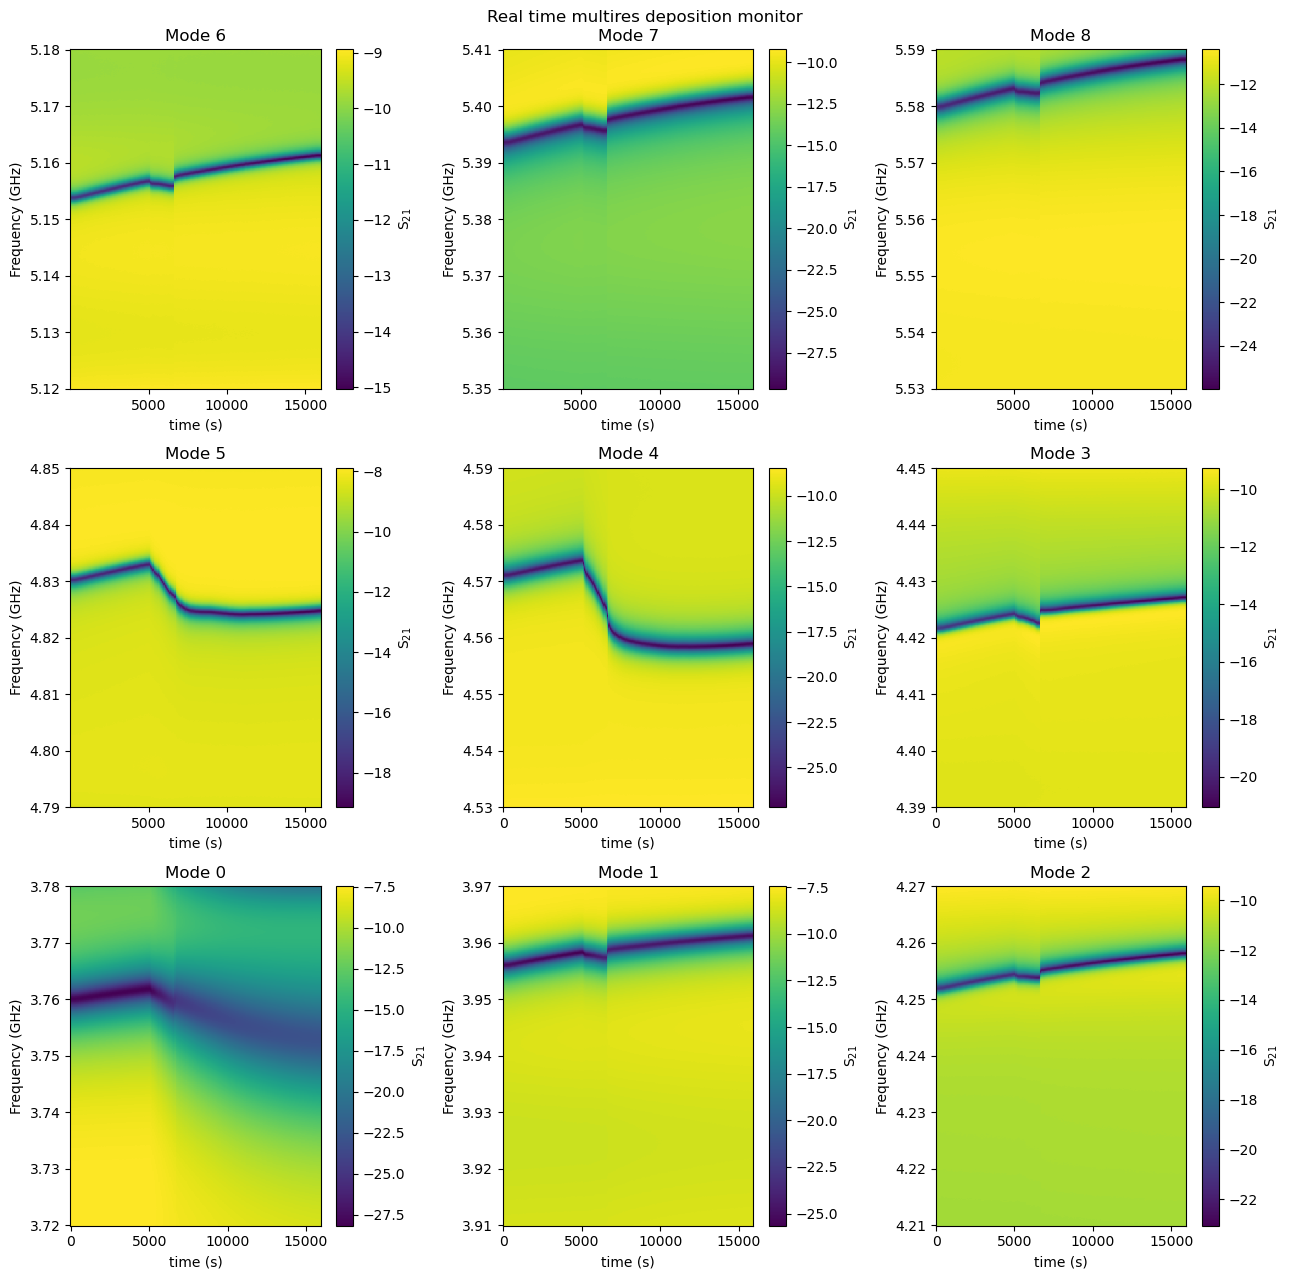

In [6]:
wait_for_stable_resistance()

current_root_array = np.linspace(np.sqrt(0.480), np.sqrt(0.300), 201)

current_array = current_root_array**2

os.makedirs(r"C:\Users\crow104\Desktop\IceT_SD\SpatialNeon\Data\LtoS2_05112026", exist_ok = True)

path = r"C:\Users\crow104\Desktop\IceT_SD\SpatialNeon\Data\LtoS2_05112026"
f_values = [3.75, 3.94, 4.24, 4.42, 4.56, 4.82, 5.15, 5.38, 5.56]


multires_liquid_cooldown_buffer(vna_addr = vna_addr, hp34461a_addr = hp34461a_addr, bkpower_addr = bkpower_addr, arduino_addr = arduino_addr, data_dir= path, current_array= current_array, buffer = 60*5, wait_time= 60, delay_time = 3, del_time = 3, f_vals = f_values, BW = 1E3, span = 60, power = -20, n_points = 501, name = 'powerminus20')

Channel set to 2

Current set to 0.48
A


c:\Users\crow104\Desktop\IceT_SD\SpatialNeon\Routines\res_to_temp.py:48: RuntimeWarning: divide by zero encountered in log
  log_T = np.log(T)


success!
Channel set to 2

Voltage set to 30
V
4.560000

10.00

0

60
Started at 2026-05-12 21_23_31.189995
4571280000.000000

Channel set to 2

Current set to 0.48
A
4571280000.000000

Channel set to 2

Current set to 0.475987
A
4571280000.000000

Channel set to 2

Current set to 0.471992
A
4571280000.000000

Channel set to 2

Current set to 0.468013
A
4571400000.000000

Channel set to 2

Current set to 0.46405
A
4571520000.000000

Channel set to 2

Current set to 0.460105
A
4571640000.000000

Channel set to 2

Current set to 0.456177
A
4571760000.000000

Channel set to 2

Current set to 0.452265
A
4572000000.000000

Channel set to 2

Current set to 0.44837
A
4572120000.000000

Channel set to 2

Current set to 0.444493
A
4572240000.000000

Channel set to 2

Current set to 0.440631
A
4572480000.000000

Channel set to 2

Current set to 0.436787
A
4572600000.000000

Channel set to 2

Current set to 0.43296
A
4572840000.000000

Channel set to 2

Current set to 0.429149
A
4572960000.000000

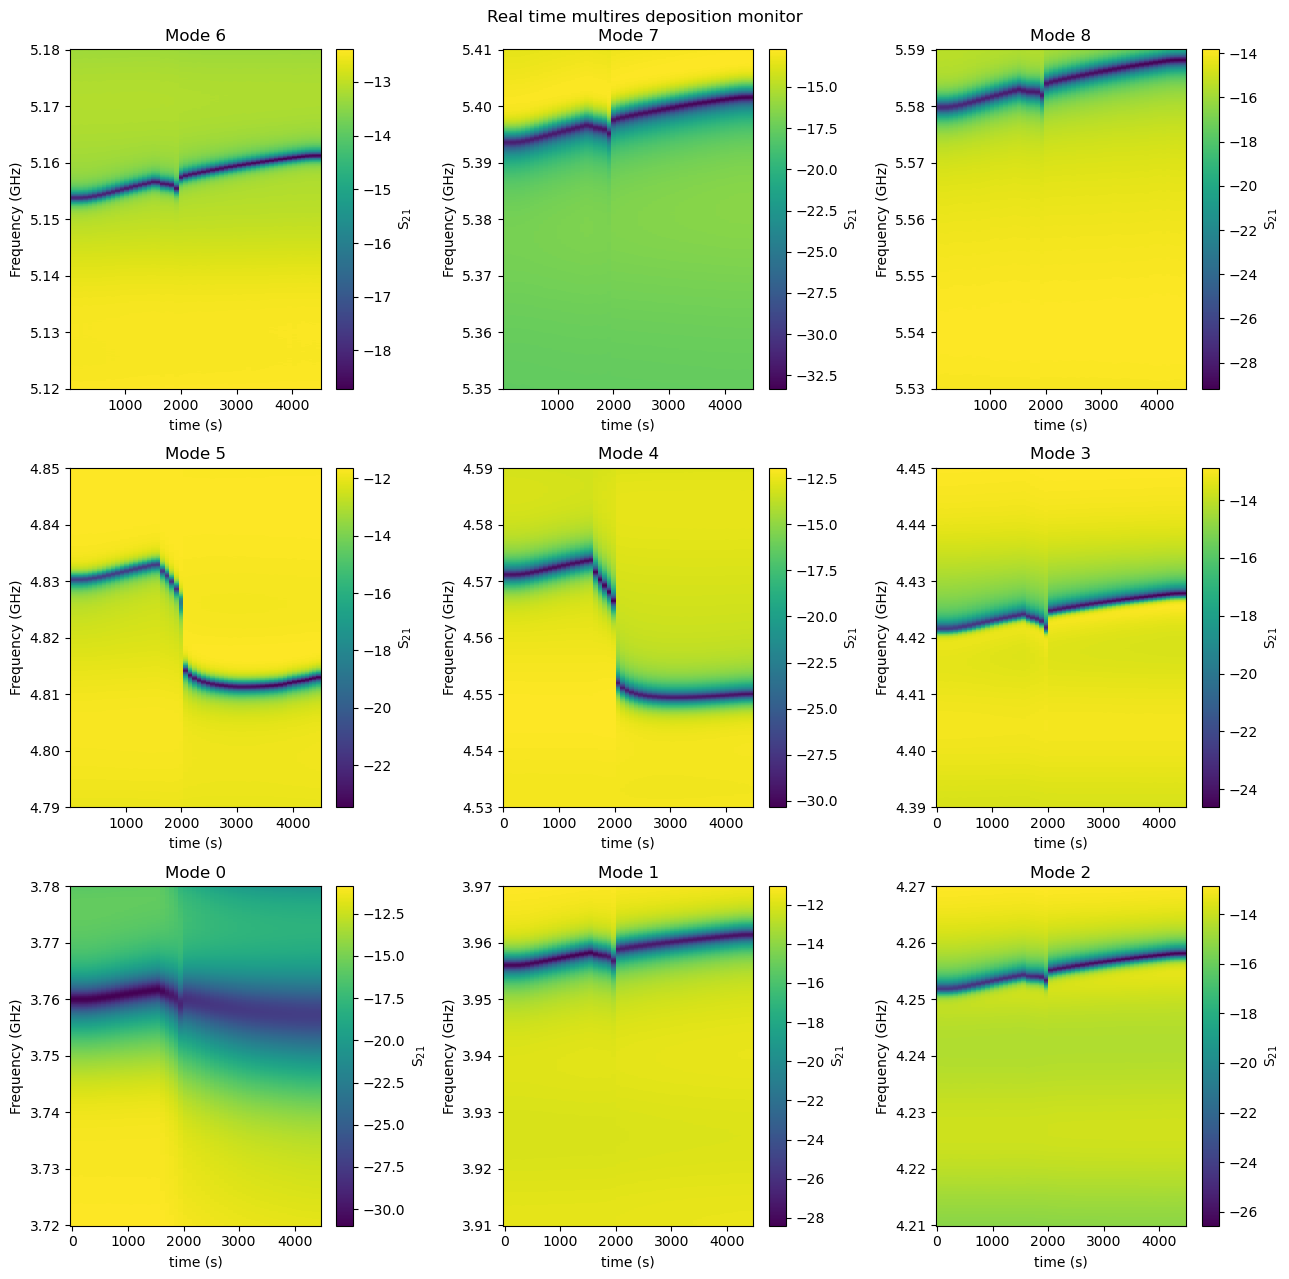

In [ ]:

set_current(bkpower_addr, 2, 0.48)
wait_for_stable_resistance()

current_root_array = np.linspace(np.sqrt(0.480), np.sqrt(0.300), 51)

current_array = current_root_array**2

os.makedirs(r"C:\Users\crow104\Desktop\IceT_SD\SpatialNeon\Data\LtoS_singlemode_05132026", exist_ok = True)

path = r"C:\Users\crow104\Desktop\IceT_SD\SpatialNeon\Data\LtoS_singlemode_05132026"
f_values = [4.56]


multires_singlefocus(vna_addr = vna_addr, hp34461a_addr = hp34461a_addr, bkpower_addr = bkpower_addr, arduino_addr = arduino_addr, lo_addr= lo_addr, focus_mode= f_values[4], focus_mode_power= 10.00, data_dir= path, current_array= current_array, buffer = 60*5, wait_time= 60, delay_time = 3, del_time = 3, f_vals = f_values, BW = 1E3, span = 60, power = 0, n_points = 501, name = 'power0mode4focus')

Channel set to 2

Voltage set to 30
V
60
Started at 2026-05-13 17_26_40.296537
Channel set to 2

Current set to 0.48
A
Channel set to 2

Current set to 0.475987
A
Channel set to 2

Current set to 0.471992
A
Channel set to 2

Current set to 0.468013
A
Channel set to 2

Current set to 0.46405
A
Channel set to 2

Current set to 0.460105
A
Channel set to 2

Current set to 0.456177
A
Channel set to 2

Current set to 0.452265
A
Channel set to 2

Current set to 0.44837
A
Channel set to 2

Current set to 0.444493
A
Channel set to 2

Current set to 0.440631
A
Channel set to 2

Current set to 0.436787
A
Channel set to 2

Current set to 0.43296
A
Channel set to 2

Current set to 0.429149
A
Channel set to 2

Current set to 0.425356
A
Channel set to 2

Current set to 0.421579
A
Channel set to 2

Current set to 0.417819
A
Channel set to 2

Current set to 0.414076
A
Channel set to 2

Current set to 0.410349
A
Channel set to 2

Current set to 0.40664
A
Channel set to 2

Current set to 0.402947
A
Chann

KeyError: 6

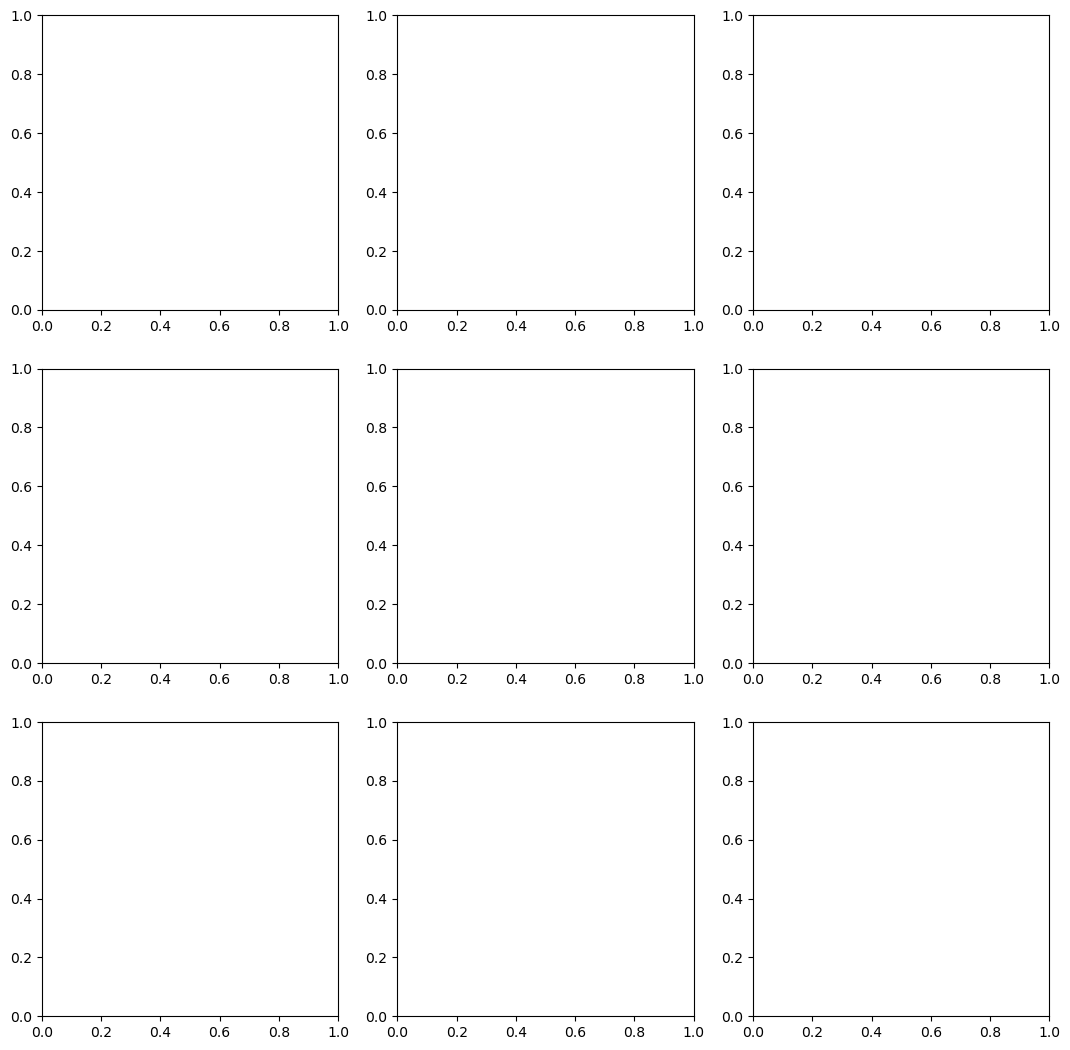

In [8]:

current_root_array = np.linspace(np.sqrt(0.480), np.sqrt(0.300), 51)

current_array = current_root_array**2

os.makedirs(r"C:\Users\crow104\Desktop\IceT_SD\SpatialNeon\Data\LtoS_singlemode_05132026", exist_ok = True)

path = r"C:\Users\crow104\Desktop\IceT_SD\SpatialNeon\Data\LtoS_singlemode_05132026"
f_values = [4.56]


multires_liquid_cooldown_buffer(vna_addr = vna_addr, hp34461a_addr = hp34461a_addr, bkpower_addr = bkpower_addr, arduino_addr = arduino_addr, data_dir= path, current_array= current_array, buffer = 60*5, wait_time= 60, delay_time = 6, del_time = 3, f_vals = f_values, BW = 1E3, span = 60, power = 10, n_points = 501, name = 'power10mode4focus')